# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
W, H, C, B = 1920, 1080, 3, 1                     
frame_bytes = W * H * C * B
frame_mb = frame_bytes / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = FPS * 24 * 60 * 60    

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
N_CAM = 400
fleet_tb = frame_bytes * frames_per_day * N_CAM / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * C * B
small_frames_per_day = 10 * 24 * 60 * 60
fleet_tb_small = small_frame_bytes * small_frames_per_day * N_CAM / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100


print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_
One spatial piece of evidence lost. Going from 1920×1080 to 640×360 keeps only 11.11% of the pixels (each output pixel is an average of about 3×3 original pixels), and raster interpolation (Slide 13) can only *re-estimate* values between the pixels that survive. It cannot bring back detail that was averaged away. So fine, high-frequency detail such as the characters on a licence plate, a face, a logo or a small object in someone's hand is gone for good. Upscaling the 360p video later just gives a smoother, blurrier version of the same information, never the lost detail.

One temporal piece of evidence lost. At 10 fps the frames are 100 ms apart instead of 33 ms, so fast events move a long way between frames, and anything shorter than 0.1 s can fall completely between two frames. This is the correspondence problem (Slides 36–37): the viewer can no longer be sure which blob in frame *n* is the same object in frame *n+1*, or in what order things happened. For example, whether a car clipped a pedestrian or the pedestrian stepped into the car, or who moved first in a scuffle, could no longer be established. Neither loss can be undone after the data is discarded, which is why the downsampling decision has to be made before the incident, not after it.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

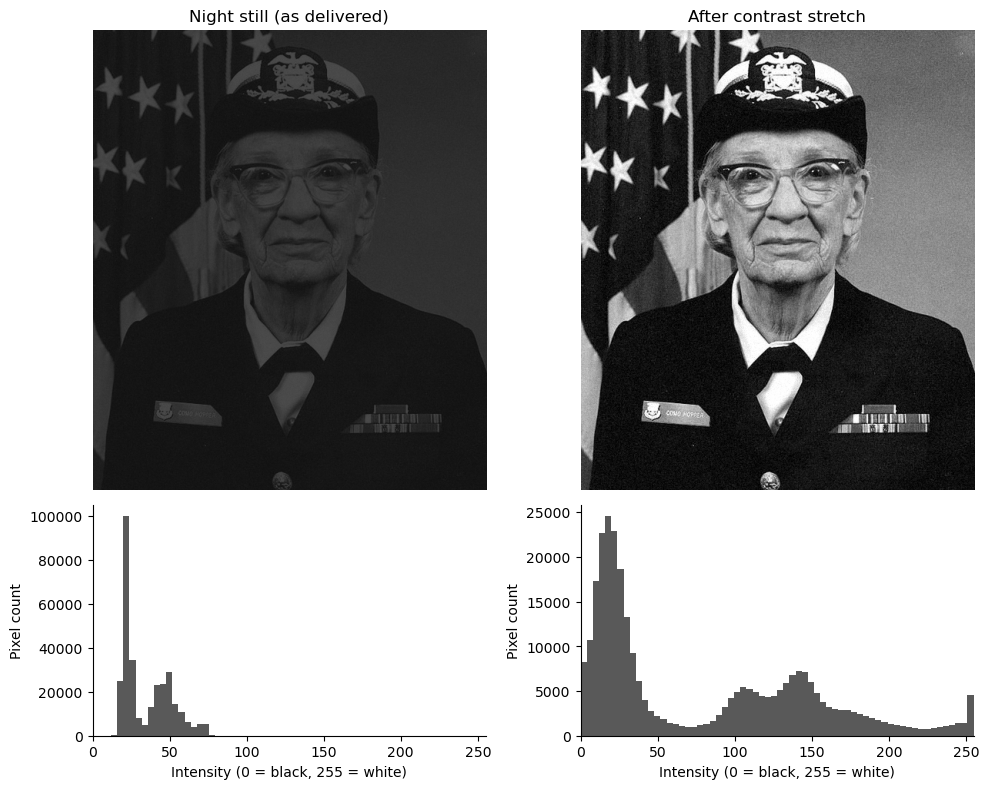

Contrast before: 0.609  ->  after: 1.000
Occupied range before: 18-73 of 0-255


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

p1_s, p99_s = np.percentile(stretched, [1, 99])
c_after = michelson(p99_s, p1_s)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (data, title) in enumerate([(night_still, "Night still (as delivered)"),
                                     (stretched, "After contrast stretch")]):
    axes[0, col].imshow(data, cmap="gray", vmin=0, vmax=255)   # fixed 0-255 scale so the comparison is fair
    axes[0, col].set_title(title)
    axes[0, col].axis("off")
    axes[1, col].hist(data.ravel(), bins=64, range=(0, 255), color="0.35")
    axes[1, col].set_xlim(0, 255)
    axes[1, col].set_xlabel("Intensity (0 = black, 255 = white)")
    axes[1, col].set_ylabel("Pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")
print(f"Occupied range before: {p1:.0f}-{p99:.0f} of 0-255")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_
Shape of the histogram. The night image's histogram is *narrow* and *pushed to the dark (left) end*. Almost all pixels sit between about 18 and 73 out of 255, with a main peak near 22 and a smaller hump around 45–50. Nothing reaches the bright end and nothing is clipped at 0 or 255. In the lecture's vocabulary this is a dark (under-exposed), low-contrast, low-key image: the Michelson contrast is only about 0.61 on the robust 1st/99th-percentile measure, and the image uses only roughly a fifth of the available intensity range. So the problem is a compressed dynamic range, not clipping or lost data.

Why stretching helped without adding information. The stretch is just a linear remap of the intensity values that were already there. The relative differences between pixels (the face, the flag stripes, the edges) were already in the 18–73 range, but a difference of a few grey levels near black is almost invisible on screen and to the eye. Spreading the same values over 0–255 makes those differences large enough to see. No new detail is created. Only about 55 distinct grey levels existed to begin with, and the sensor noise gets amplified by the same factor (about 4.6×), as does everything else. The roughly 1% of pixels pushed to the extremes are clipped, which is a small deliberate loss.

Why the histogram alone couldn't tell us what is in the picture. A histogram only counts how many pixels have each intensity and throws away where they are. Rearranging or shuffling the pixels of the image gives exactly the same histogram, so very different images, including pure noise, can share one (Slide 18, "Same Histogram ≠ Same Image"). The histogram is good for diagnosing the problem (exposure and contrast) and for choosing the fix. Recognising a person, a flag or a licence plate needs the spatial arrangement of pixels, which only the image itself shows.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (<3 px/s):  68.7 s -> 78.1 s
Running  (>25 px/s): 78.6 s -> 86.0 s
Audio event: frame 2250 (75.00 s) | Lighting event: frame 3000 (100.00 s)


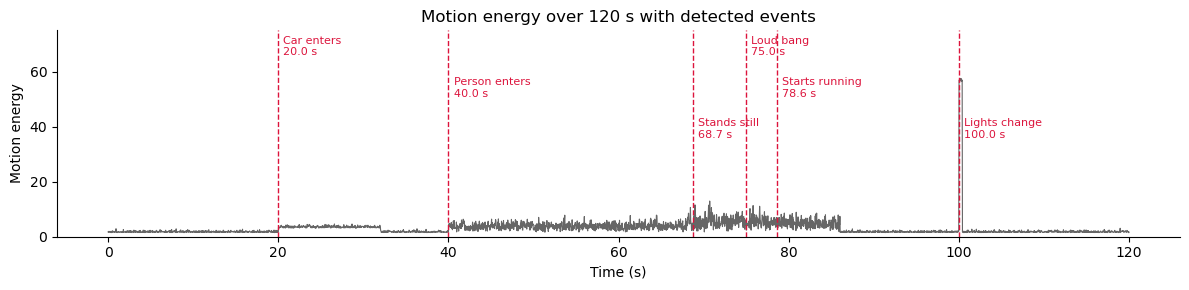

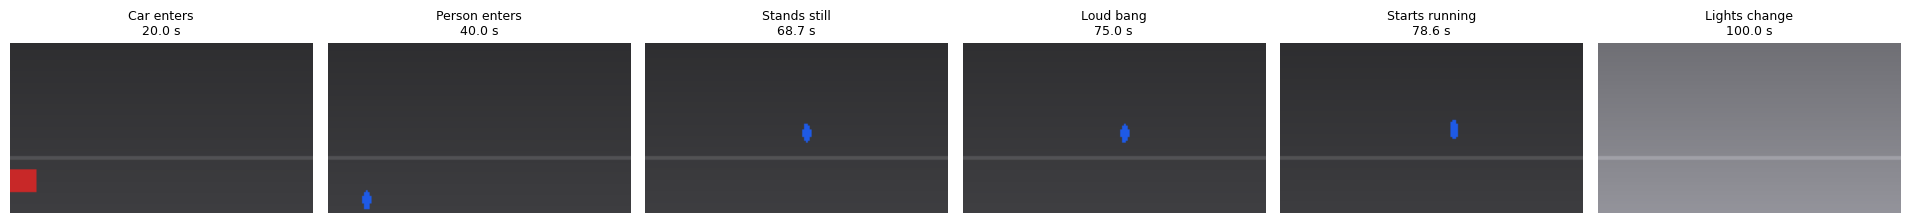

In [4]:
# TODO 1: person speed (px/s)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))

# TODO 2: standing / running time ranges (print the first and last time of each)
t = cctv.time_s.values
standing_idx = np.where(speed < 3)[0]
running_idx = np.where(speed > 25)[0]
print(f"Standing (<3 px/s):  {t[standing_idx[0]]:.1f} s -> {t[standing_idx[-1]]:.1f} s")
print(f"Running  (>25 px/s): {t[running_idx[0]]:.1f} s -> {t[running_idx[-1]]:.1f} s")

# TODO 3: event frame indices
audio_event_idx = int(np.argmax(cctv.audio_level_db.values > -20))              # first frame above -20 dB
lighting_event_idx = int(np.argmax(cctv.mean_brightness.diff().abs().values > 40))  # first one-frame jump > 40
print(f"Audio event: frame {audio_event_idx} ({t[audio_event_idx]:.2f} s) | "
      f"Lighting event: frame {lighting_event_idx} ({t[lighting_event_idx]:.2f} s)")
person_in = int(cctv.person_x.first_valid_index())
stand_start = int(standing_idx[0])
run_start = int(running_idx[0])
car_in = int(cctv.car_x.first_valid_index())
events = sorted([("Car enters", car_in),
                 ("Person enters", person_in),
                 ("Stands still", stand_start),
                 ("Loud bang", audio_event_idx),
                 ("Starts running", run_start),
                 ("Lights change", lighting_event_idx)], key=lambda e: e[1])

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color="0.4", lw=0.8)
ax.set_ylim(0, 75)                                       # headroom for staggered labels
for k, (label, i) in enumerate(events):
    ax.axvline(t[i], color="crimson", ls="--", lw=1)
    ax.text(t[i] + 0.6, 73 - 15 * (k % 3), f"{label}\n{t[i]:.1f} s",
            color="crimson", fontsize=8, va="top")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
ax.set_title("Motion energy over 120 s with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3.2 * len(events), 2.6))
for ax, (label, i) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i]))
    ax.set_title(f"{label}\n{t[i]:.1f} s", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
With uniform keyframes every 20 s (frames at 0, 20, 40, 60, 80, 100 s), the most likely event to be missed is the loud bang at 75 s. It lasts only about 2 s, so a sample would land in it only about 1 time in 10. The nearest uniform frames are at 60 s (person still walking) and 80 s (person already running), so the briefing would show the person walking and then running with nothing in between. The reviewer would also miss the other short transitions in that window: the person stopping at 68.7 s and starting to run at 78.6 s. The lights coming on at 100 s is a persistent change, so a uniform frame at 100 s or 120 s would show a brighter scene, but only by luck of the sampling offset, and it would give no precise time for when it changed (it could have happened anywhere in the previous 20 s). In short, uniform sampling is blind to *when* things change, and the interesting moments here are brief and bunched together.

The approach used instead is content-based keyframe extraction (Slide 40): keyframes are chosen where the content changes (motion, audio level, brightness) rather than at fixed time intervals, so the frames are dense where activity is high and sparse where nothing happens.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

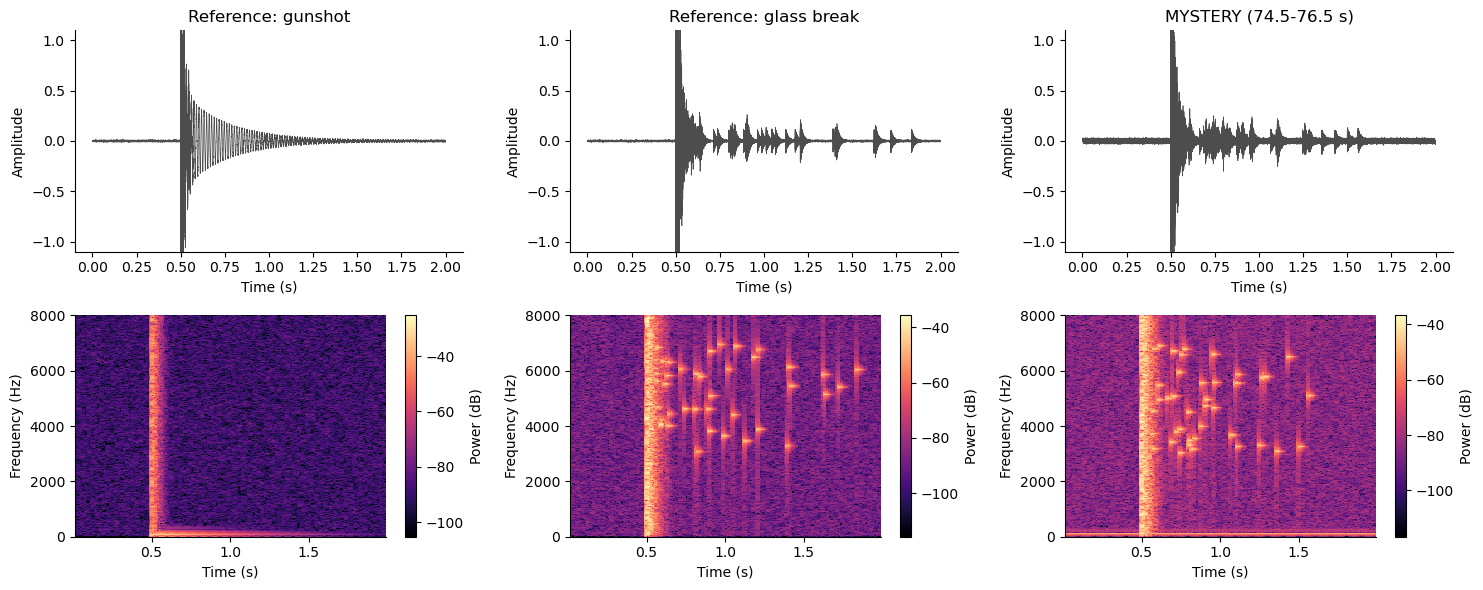

{'Reference: gunshot': np.float64(0.003), 'Reference: glass break': np.float64(0.989), 'MYSTERY (74.5-76.5 s)': np.float64(0.873)}
{'Reference: gunshot': np.float64(0.0030352610136762815), 'Reference: glass break': np.float64(0.9891874044148661), 'MYSTERY (74.5-76.5 s)': np.float64(0.8734552491106998)}
Verdict: the mystery sound is GLASS BREAKING - 87% of its post-impact energy is above 3 kHz (reference glass 99% vs reference gunshot 0%).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
spec = {}
for col, (name, x) in enumerate(clips.items()):
    tt = np.arange(x.size) / FS
    axes[0, col].plot(tt, x, color="0.3", lw=0.5)
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Time (s)"); axes[0, col].set_ylabel("Amplitude")
    axes[0, col].set_ylim(-1.1, 1.1)                                    # same scale so amplitudes compare fairly

    f, ts, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    spec[name] = (f, ts, Sxx)
    S_db = 10 * np.log10(Sxx + 1e-12)
    im = axes[1, col].pcolormesh(ts, f, S_db, shading="auto", cmap="magma",
                                 vmin=S_db.max() - 80, vmax=S_db.max())
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Frequency (Hz)")
    fig.colorbar(im, ax=axes[1, col], label="Power (dB)")

plt.tight_layout(); plt.show()


# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
IMPACT = 0.5
hf_fraction = {}
for name, (f, ts, Sxx) in spec.items():
    win = (ts >= IMPACT + 0.2) & (ts <= IMPACT + 1.2)                  
    total = Sxx[:, win].sum()
    high = Sxx[f > 3000][:, win].sum()
    hf_fraction[name] = high / total

print({k: round(v, 3) for k, v in hf_fraction.items()})
print(hf_fraction)

# TODO 4: verdict
THRESH = 0.5
m = hf_fraction["MYSTERY (74.5-76.5 s)"]
kind = "GLASS BREAKING" if m > THRESH else "GUNSHOT"
print(f"Verdict: the mystery sound is {kind} - {m:.0%} of its post-impact energy is above 3 kHz "
      f"(reference glass {hf_fraction['Reference: glass break']:.0%} vs reference gunshot {hf_fraction['Reference: gunshot']:.0%}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
Waveforms alone. No, not with confidence. All three waveforms show the same thing at the impact: a very loud spike at 0.5 s that fills the whole amplitude range. The waveform shows *when* something loud happened and how the loudness decays, but not *what the sound is made of*. After the spike, the gunshot's tail is a smooth decaying low-frequency oscillation, while the glass shows irregular small bursts, so a careful eye might suspect a difference. But the mystery clip also has background hum and noise, which blurs that envelope, and the amplitude alone would not be enough evidence to decide between two responses as different as a shooting and a break-in.

What the spectrogram adds. It shows all three dimensions at once (Slide 57): time on the x-axis, frequency on the y-axis, and magnitude (power, in dB, shown as colour). That reveals which frequencies are present at each moment, which a waveform hides inside one squiggly line.

What decided the verdict. The gunshot reference shows a single vertical stripe at the impact followed by a thin low-frequency horizontal band (the low boom) and nothing in the high frequencies afterwards. The glass reference and the mystery clip both show the impact stripe followed by scattered high-frequency specks between roughly 3 and 7 kHz over the next second or so (the glass tinkling). The mystery clip matches that pattern. The numbers agree: in the 0.2–1.2 s after the impact, about 87% of the mystery clip's energy is above 3 kHz, against about 99% for the glass reference and 0.3% for the gunshot reference. Verdict: glass breaking, not a gunshot.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

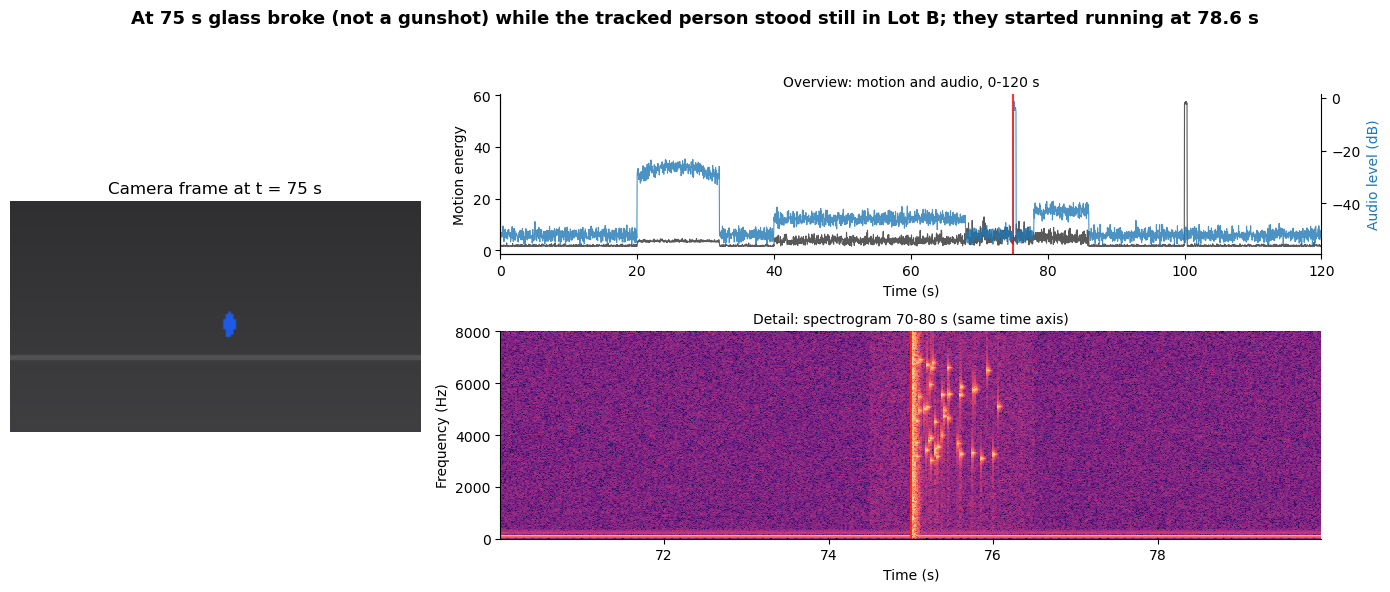

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
# 1. video frame at t = 75 s (left, spans both rows)
ax_img = fig.add_subplot(gs[:, 0])
sel_idx = int(round(t_sel * FPS))
ax_img.imshow(render_frame(cctv.iloc[sel_idx]))
ax_img.set_title(f"Camera frame at t = {t_sel:.0f} s")
ax_img.axis("off")

# 2. full 120 s motion + audio timeline (top right) with marker at 75 s
ax_tl = fig.add_subplot(gs[0, 1])
ax_tl.plot(cctv.time_s, cctv.motion_energy, color="0.35", lw=0.8, label="Motion energy")
ax_tl.set_ylabel("Motion energy")
ax_tl.set_xlim(0, 120)
ax_au = ax_tl.twinx()
ax_au.plot(cctv.time_s, cctv.audio_level_db, color="tab:blue", lw=0.8, alpha=0.8, label="Audio level (dB)")
ax_au.set_ylabel("Audio level (dB)", color="tab:blue")
ax_au.spines["right"].set_visible(True)
ax_tl.axvline(t_sel, color="red", lw=1.5, alpha=0.8)
ax_tl.set_title("Overview: motion and audio, 0-120 s", fontsize=10)
ax_tl.set_xlabel("Time (s)")

# 3. spectrogram of x_audio (70-80 s) with the same marker (bottom right)
ax_sp = fig.add_subplot(gs[1, 1])
mask = (t_audio >= 70) & (t_audio < 80)
f, ts, Sxx = signal.spectrogram(x_audio[mask], fs=FS, nperseg=512, noverlap=384)
S_db = 10 * np.log10(Sxx + 1e-12)
ax_sp.pcolormesh(70 + ts, f, S_db, shading="auto", cmap="magma", vmin=S_db.max() - 80, vmax=S_db.max())
ax_sp.set_ylim(0, 8000)
ax_sp.axvline(t_sel, color="red", lw=1.5, alpha=0.8)
ax_sp.set_xlabel("Time (s)"); ax_sp.set_ylabel("Frequency (Hz)")
ax_sp.set_title("Detail: spectrogram 70-80 s (same time axis)", fontsize=10)

# 4. conclusion-style title
fig.suptitle("At 75 s glass broke (not a gunshot) while the tracked person stood still in Lot B; "
             "they started running at 78.6 s", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_
If the audio were offset by +2 s from the video, the bang would be drawn at about 77 s on the shared time axis instead of 75 s. At the red marker (75 s), the video frame would show the person standing still while the audio panel showed only quiet background. The glass break would then appear after the marker, only about 1.6 s before the person starts running at 78.6 s instead of about 3.6 s before. That would give a wrong story: a reader could conclude that the person ran off almost at once after the sound, or that the sound and the stillness are unrelated, and the timestamps given to police or insurers would be wrong by 2 s. The mistake would be most visible in the spectrogram panel (bottom right), because the bright vertical impact stripe would not line up with the red 75 s marker, and also in the top timeline, where the audio spike would sit to the right of the marker instead of on it. Neither panel would show it as an error by itself. It only becomes visible because all panels share one time axis and one marker, which is the point of synchronisation (Slide 59). The three panels with two y-axes are also already quite dense, so the briefing should keep the markers and labels minimal to avoid the information overload that Slide 61 warns about.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

At 75.0 s in Parking Lot B the camera microphone recorded a glass-breaking sound, not a gunshot, while the one tracked person, who had been walking since 40 s, stood still from 68.7 s to 78.1 s and then ran from 78.6 s to 86.0 s; the lights came on at 100 s. The glass-break call comes from the spectrogram, where the sound shows the scattered 3–7 kHz specks of the glass reference (87% of post-impact energy above 3 kHz, against 0.3% for the gunshot reference), so the glass-break response should be triggered, not the shooting response. If I could show only one view first, it would be the synchronized one-screen view, because it follows the lecture's structure → pattern → change → event → meaning chain: the timeline gives the overview and picks out the changes, content-based keyframes give the picture at each event, and the spectrogram (time × frequency × magnitude) explains the meaning of the sound, all on one common time axis. For storage, uncompressed 1080p at 30 fps across 400 cameras would be about 5,866 TB per day, so the routine policy should downsample (360p at 10 fps is about 217 TB per day, 27× less) and compress, and keep full-quality recording only around events flagged by motion or audio triggers. The one thing that policy must not sacrifice is the audio bandwidth and sampling rate (at least 16 kHz, so content above 3 kHz survives), because that high-frequency content was the only thing that separated glass from a gunshot; a close second is accurate timestamps shared by the video and audio.